In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
df = pd.read_csv('C:\\Users\\anish\\Documents\\Practice_Task_1\\cleaned_house_rent.csv', parse_dates=['Posted On'])
df.shape

(4230, 12)

In [23]:
df['Floor'].value_counts().head(15)
df[~df['Floor'].str.contains('out of')]['Floor'].value_counts()

Floor
1         2
3         1
Ground    1
Name: count, dtype: int64

In [25]:
def parse_floor(x):
    x = str(x).strip()
    if 'out of' in x :
        cur, tot = x.split('out of')
    else:
        cur, tot = x, np.nan
    mapping = {'Ground' : 0, 'Upper Basement': -1, 'Lower Basement' : -2}
    cur  = mapping.get(cur, cur)
    return pd.Series([pd.to_numeric(cur, errors='coerce'), pd.to_numeric(tot, errors = 'coerce')])

df[['Floor_No', 'Total_Floors']] = df['Floor'].apply(parse_floor)

print(df[['Floor_No', 'Total_Floors']].isnull().sum())
print('Floor_No > Total_Floors:', (df['Floor_No'] > df['Total_Floors']).sum())

Floor_No        891
Total_Floors      4
dtype: int64
Floor_No > Total_Floors: 2


In [26]:
df['Posted On'].min(), df['Posted On'].max()
df['Area Locality'].nunique()

2073

In [27]:
df['Size_per_BHK'] = df['Size'] / df['BHK']
df['Bath_per_BHK'] = df['Bathroom'] / df['BHK']

In [28]:
df['log_rent'] = np.log1p(df['Rent'])

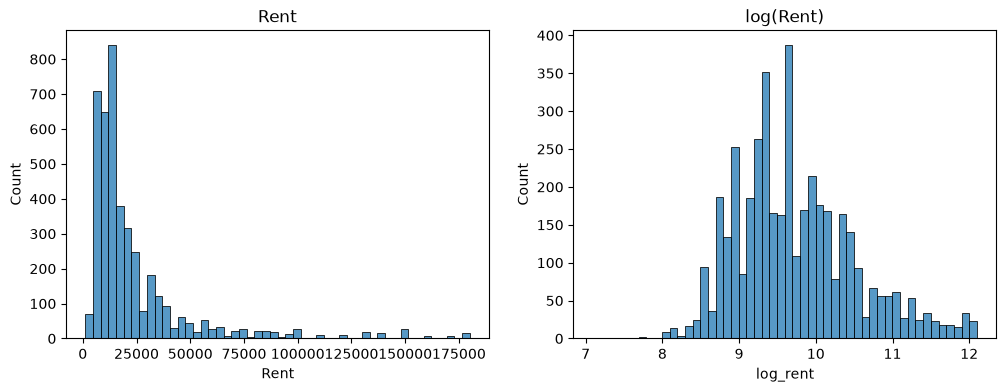

In [29]:
fig, ax = plt.subplots(1, 2, figsize = (12, 4))
sns.histplot(df['Rent'], bins=50, ax=ax[0]); ax[0].set_title('Rent')
sns.histplot(df['log_rent'], bins=50, ax=ax[1]); ax[1].set_title('log(Rent)')
plt.show()

In [36]:
furnish_map = {'Unfurnished': 0, 'Semi-Furnished': 1, 'Furnished': 2}
df['Furnishing_Level'] = df['Furnishing Status'].map(furnish_map)

drop_cols = ['Posted On', 'Floor', 'Area Locality', 'Furnishing Status',
             'rent_per_sqft', 'Rent']

df_model = pd.get_dummies(
    df.drop(columns=drop_cols, errors='ignore'),
    columns=['City', 'Area Type', 'Tenant Preferred', 'Point of Contact'],
    drop_first=True, dtype=int
)
df_model.head()

,BHK,Size,Bathroom,Floor_No,Total_Floors,Size_per_BHK,Bath_per_BHK,log_rent,Furnishing_Level,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Area Type_Carpet Area,Area Type_Super Area,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Builder,Point of Contact_Contact Owner
0,2,1100,2,NaN,2.0,550.0,1.0,9.210440,0,0,0,0,1,0,0,1,1,0,0,1
1,2,800,1,1.0,3.0,400.0,0.5,9.903538,1,0,0,0,1,0,0,1,1,0,0,1
2,2,1000,1,1.0,3.0,500.0,0.5,9.741027,1,0,0,0,1,0,0,1,1,0,0,1
3,2,800,1,1.0,2.0,400.0,0.5,9.210440,0,0,0,0,1,0,0,1,1,0,0,1
4,2,850,1,1.0,2.0,425.0,0.5,8.922792,0,0,0,0,1,0,1,0,0,0,0,1


In [37]:
print([c for c in df_model.columns if 'rent' in c.lower()])

['log_rent']


In [41]:
x = df_model.drop(columns = 'log_rent')
y = df_model['log_rent']

print('x shape:', x.shape, "| y shape:", y.shape)
print("Missing values:", x.isnull().sum().sum())
print(x.dtypes.value_counts())


x shape: (4230, 19) | y shape: (4230,)
Missing values: 895
int64      15
float64     4
Name: count, dtype: int64


In [42]:
df_model.to_csv('model_ready.csv', index=False)

In [48]:
print([c for c in x.columns if 'rent' in c.lower()])

[]


## Feature Engineering Decisions

**1. Floor column**
The `Floor` column is text like "1 out of 3". I split it into two numeric features: `Floor_No` and `Total_Floors`. Special values were handled as follows: "Ground" = 0, "Upper Basement" = -1, "Lower Basement" = -2. Rows with no "out of" part had a missing `Total_Floors`, which I filled with [your choice and reason, e.g. the same value as `Floor_No`].

**2. Dropping `Area Locality`**
It has [N] unique values (check with `df['Area Locality'].nunique()`) across only [~4,000] rows. One-hot encoding it would add hundreds of sparse columns and cause overfitting, because most localities appear only a few times. City already captures most of the location effect.

**3. Encoding choices**
- `Furnishing Status` is **ordinal** (Unfurnished < Semi-Furnished < Furnished), so I mapped it to 0/1/2 to keep the order.
- `City`, `Area Type`, `Tenant Preferred` and `Point of Contact` have **no natural order**, so I used one-hot encoding (`drop_first=True` to avoid redundant columns).

**4. Why `rent_per_sqft` cannot be a feature (data leakage)**
`rent_per_sqft = Rent / Size`, so it is built directly from the target. A model would be given part of the answer it is trying to predict and would score unrealistically well, but it would fail on new houses where the rent is unknown. This is called **data leakage**, so I removed it (and `Rent` itself).

**5. Why `log_rent` as the target**
Rent is strongly right-skewed. The log transform makes it much closer to a bell shape, which helps linear models and reduces the influence of very expensive listings. Predictions can be converted back with `np.expm1()`.

**Posted On:** the data spans only [min date] to [max date], about [N] months, so there is no real time trend to learn from. I dropped the column.